In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [3]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum().sum()

np.int64(0)

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [7]:
# Q1
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col:26} {auc:.3f}')

number_of_courses_viewed   0.723
annual_income              0.608
interaction_count          0.765
lead_score                 0.788


In [8]:
# Q2
features = categorical + numerical

def train(df, y, C=1.0):
    dicts = df[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model

def predict(df, dv, model):
    dicts = df[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(df_val, dv, model)

round(roc_auc_score(y_val, y_pred), 3)

np.float64(0.732)

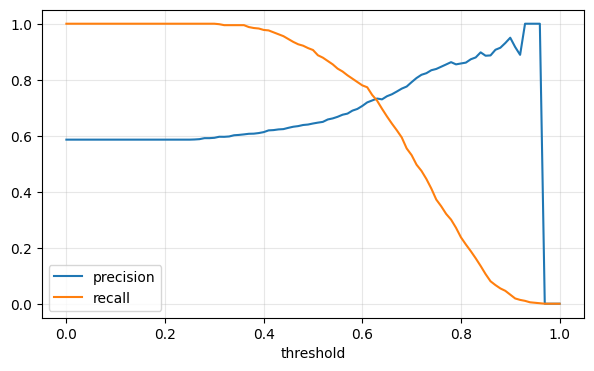

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629


In [9]:
# Q3
thresholds = np.arange(0.0, 1.01, 0.01)
scores = []

for t in thresholds:
    predict_positive = (y_pred >= t)
    actual_positive = (y_val == 1)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & ~actual_positive).sum()
    fn = (~predict_positive & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    scores.append((t, precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ignore thresholds where both are 0, then take the smallest gap
df_nonzero = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
df_nonzero['diff'] = (df_nonzero.precision - df_nonzero.recall).abs()

df_nonzero.sort_values('diff').head(3)

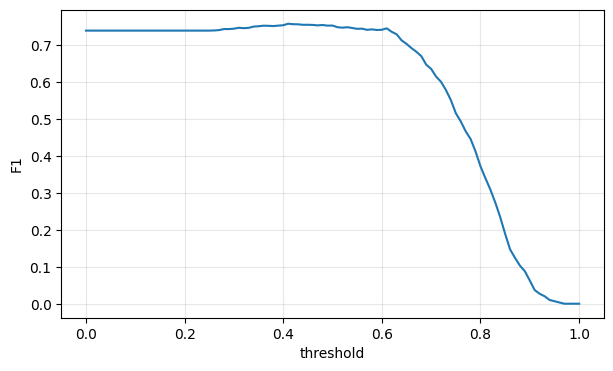

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032


In [10]:
# Q4
p = df_scores.precision
r = df_scores.recall
df_scores['f1'] = np.where(p + r > 0, 2 * p * r / (p + r), 0.0)

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold')
plt.ylabel('F1')
plt.grid(alpha=0.3)
plt.show()

df_scores.sort_values('f1', ascending=False).head(3)

In [11]:
# Q5
def cross_validate(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv, model = train(df_tr, df_tr.converted.values, C=C)
        y_pred = predict(df_va, dv, model)
        aucs.append(roc_auc_score(df_va.converted.values, y_pred))

    return aucs

aucs = cross_validate(C=1.0)
print(np.round(aucs, 3))
print('mean = %.3f, std = %.3f' % (np.mean(aucs), np.std(aucs)))

[0.731 0.73  0.736 0.741 0.721]
mean = 0.732, std = 0.007


In [12]:
# Q6
for C in [0.000001, 0.001, 1]:
    aucs = cross_validate(C)
    print('C = %-8s mean = %.3f  std = %.3f' % (C, np.mean(aucs), np.std(aucs)))

C = 1e-06    mean = 0.617  std = 0.019
C = 0.001    mean = 0.749  std = 0.010
C = 1        mean = 0.732  std = 0.007
